In [41]:
import glob

from parso.python.tree import Class

files = glob.glob("youtube-dataset\*.csv")

In [42]:
import pandas as pd
df=[]
for i in files:
    df.append(pd.read_csv(i))

In [43]:
df

[                                      COMMENT_ID  \
 0    LZQPQhLyRh80UYxNuaDWhIGQYNQ96IuCg-AYWqNPjpU   
 1    LZQPQhLyRh_C2cTtd9MvFRJedxydaVW-2sNg5Diuo4A   
 2    LZQPQhLyRh9MSZYnf8djyk0gEF9BHDPYrrK-qCczIY8   
 3            z13fwbwp1oujthgqj04chlngpvzmtt3r3dw   
 4    LZQPQhLyRh9-wNRtlZDM90f1k0BrdVdJyN_YsaSwfxc   
 ..                                           ...   
 344            z13th1q4yzihf1bll23qxzpjeujterydj   
 345        z13fcn1wfpb5e51xe04chdxakpzgchyaxzo0k   
 346          z130zd5b3titudkoe04ccbeohojxuzppvbg   
 347          z12he50arvrkivl5u04cctawgxzkjfsjcc4   
 348        z13vhvu54u3ewpp5h04ccb4zuoardrmjlyk0k   
 
                                    AUTHOR                 DATE  \
 0                               Julius NM  2013-11-07T06:20:48   
 1                             adam riyati  2013-11-07T12:37:15   
 2                        Evgeny Murashkin  2013-11-08T17:34:21   
 3                                  GsMega  2013-11-10T16:05:38   
 4                         

In [44]:
df=pd.concat(df,ignore_index=True)

In [51]:
df.head()

,CONTENT,CLASS
0,"Huh, anyway check out this you[tube] channel: ...",1
1,Hey guys check out my new channel and our firs...,1
2,just for test I have to say murdev.com,1
3,watch?v=vtaRGgvGtWQ Check this out .﻿,1
4,"Hey, check out my new website!! This site is a...",1


In [46]:
df.shape

(1955, 5)

In [47]:
df.columns

Index(['COMMENT_ID', 'AUTHOR', 'DATE', 'CONTENT', 'CLASS'], dtype='str')

In [48]:
df.drop(['COMMENT_ID','AUTHOR','DATE'],axis=1,inplace=True)

In [50]:
df.describe()

,CLASS
count,1955.000000
mean,0.513555
std,0.499944
min,0.000000
25%,0.000000
50%,1.000000
75%,1.000000
max,1.000000


In [52]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1955 entries, 0 to 1954
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   CONTENT  1955 non-null   str  
 1   CLASS    1955 non-null   int64
dtypes: int64(1), str(1)
memory usage: 30.7 KB


In [56]:
df.isnull().sum()

CONTENT    0
CLASS      0
dtype: int64

In [55]:
df.duplicated().sum()

np.int64(196)

In [57]:
df.drop_duplicates(inplace=True)

In [58]:
df["CLASS"].value_counts()

CLASS
0    919
1    840
Name: count, dtype: int64

<Axes: xlabel='CLASS', ylabel='count'>

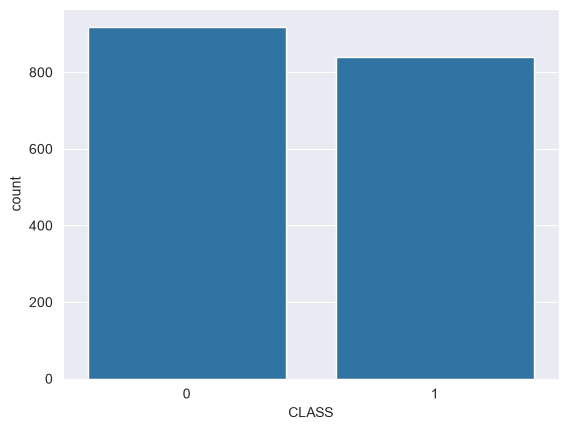

In [60]:
from matplotlib import pyplot as plt
import seaborn as sns
counts =df["CLASS"].value_counts()
sns.countplot(x="CLASS", data=df)

In [61]:
x=df["CONTENT"]
y=df["CLASS"]

In [63]:
y.shape
y.head

<bound method NDFrame.head of 0       1
1       1
2       1
3       1
4       1
       ..
1949    0
1950    0
1951    0
1953    0
1954    0
Name: CLASS, Length: 1759, dtype: int64>

In [64]:
from sklearn.model_selection import train_test_split
x_train ,x_test , y_train , y_test = train_test_split(x,y,test_size=0.2,stratify=y,random_state=42)

In [65]:
x_train.shape , x_test.shape , y_train.shape , y_test.shape

((1407,), (352,), (1407,), (352,))

In [66]:
from sklearn.feature_extraction.text import CountVectorizer
vectorizer = CountVectorizer()


In [67]:
x_train= vectorizer.fit_transform(x_train)
x_test =vectorizer.fit_transform(x_test)

In [70]:
x_train.shape

(1407, 3918)

In [71]:
x_test.shape

(352, 1461)

In [72]:
from sklearn.naive_bayes import MultinomialNB
NP=MultinomialNB()
NP.fit(x_train,y_train)


,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](2,)","[735.,672.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](2,)","[-0.65,-0.74]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](2, 3918)","[[ 2.,22., 1.,..., 1., 0., 0.], [ 4.,23., 0.,..., 0., 1., 1.]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](2, 3918)","[[-8.15,-6.11,-8.56,...,-8.56,-9.25,-9.25], [-8.29,-6.72,-9.9 ,...,-9.9 ,-9.21,-9.21]]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3918


In [73]:
NP.get_params()

{'alpha': 1.0, 'class_prior': None, 'fit_prior': True, 'force_alpha': True}

In [74]:
new_sample = ["this is a great video i lirned alot " , "i hate this content " ,"click this "]
new_sample_transformed =vectorizer.transform(new_sample)

In [76]:
NP.predict(new_sample_transformed)

ValueError: X has 1461 features, but MultinomialNB is expecting 3918 features as input.